In [1]:
import numpy as np
import pandas as pd
import os

In [3]:
import numpy as np 
import matplotlib.pyplot as plt 
import os
import glob 
from torch.utils.data import Dataset, DataLoader

import json
from pycocotools.coco import COCO
import random
from PIL import Image

import re

In [5]:
#Пути
train_dir = r"D:\rfrf\dataset\train"
test_dir = r"D:\rfrf\dataset\test"
val_dir = r"D:\rfrf\dataset\valid"


#Ищем аннотации
train_mask_annotation = glob.glob(r'D:\rfrf\dataset\train\*.json')[0]
test_mask_annotation = glob.glob(r'D:\rfrf\dataset\test\*.json')[0]
val_mask_annotation = glob.glob(r'D:\rfrf\dataset\valid\*.json')[0]


In [7]:
import json

with open( train_mask_annotation, "r") as f:
    data = json.load(f)

print(data["annotations"][0])
print(type(data))

{'id': 0, 'image_id': 0, 'category_id': 1, 'bbox': [145, 239, 168.75, 162.5], 'area': 27421.875, 'segmentation': [[313.75, 238.75, 145, 238.75, 145, 401.25, 313.75, 401.25, 313.75, 238.75]], 'iscrowd': 0}
<class 'dict'>


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


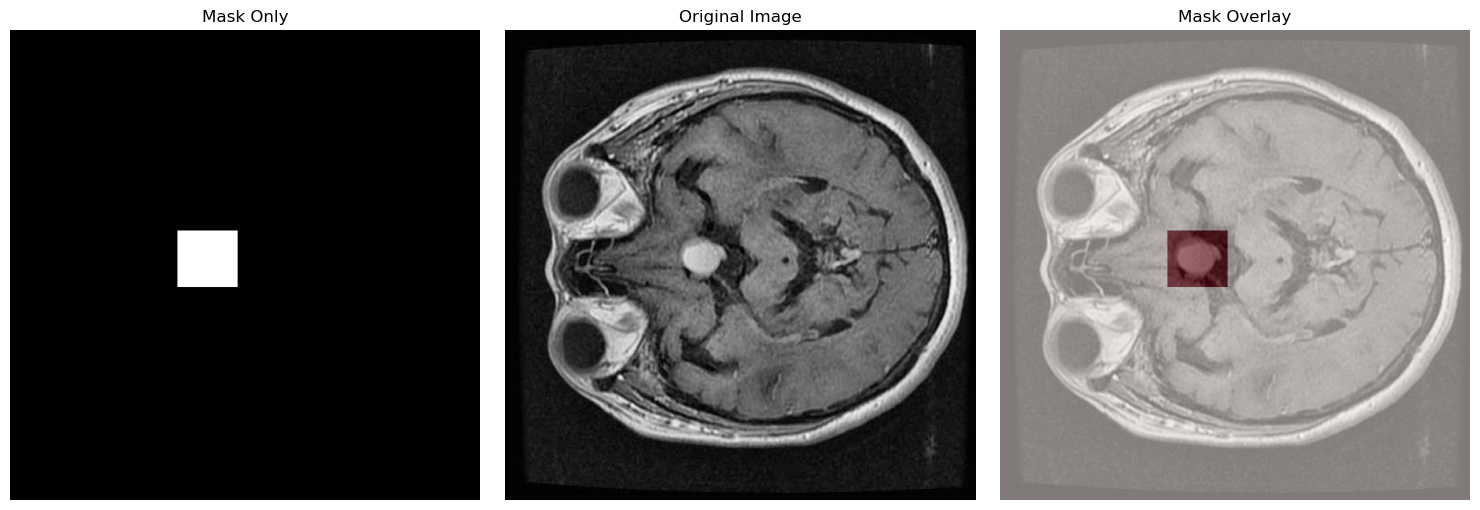

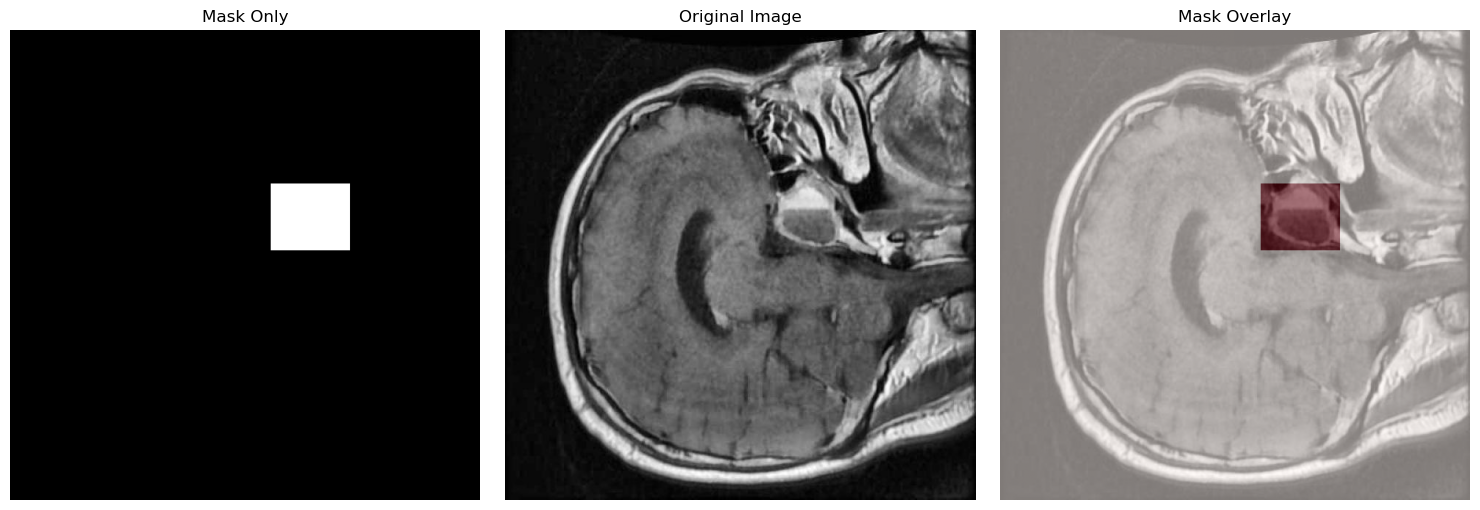

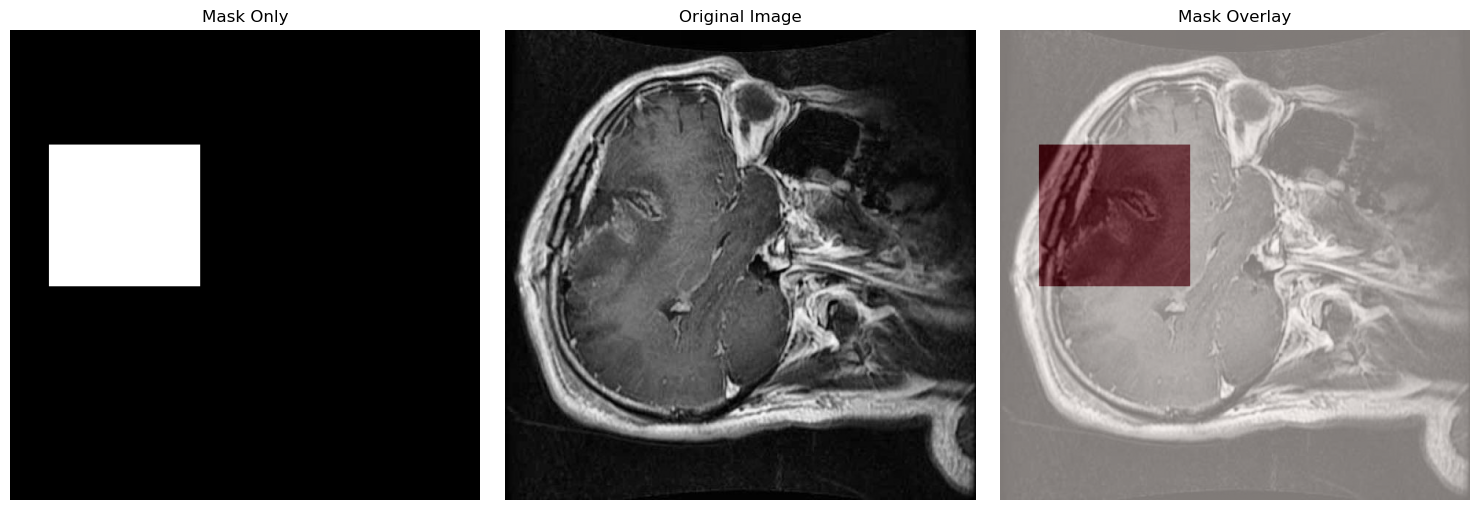

In [11]:
#Выводим три случайных изображения и накладываем маски
coco = COCO(train_mask_annotation)

image_ids = random.sample(coco.getImgIds(), 3)

for i, image_id in enumerate(image_ids):
    
    image_info = coco.loadImgs(image_id)[0]
    img_path = os.path.join(train_dir, image_info['file_name'])
    
    image = Image.open(img_path)
    
    mask = np.zeros((image_info['height'], image_info['width']))
    
    ann_ids = coco.getAnnIds(imgIds=image_id)
    anns = coco.loadAnns(ann_ids)
    
    for ann in anns:
        mask = np.maximum(mask, coco.annToMask(ann))

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(mask, cmap='gray')
    plt.title('Mask Only')
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.imshow(image)
    plt.title('Original Image')
    plt.axis('off')
    
    plt.subplot(1, 3, 3)
    plt.imshow(image)
    plt.imshow(mask, alpha=0.5, cmap='Reds')
    plt.title('Mask Overlay')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

In [12]:
import torch
import torch.nn as nn 
from torch.utils.data import DataLoader , Dataset
from torch.nn import functional 
from torchvision import transforms  as T
import albumentations as A
from albumentations.pytorch import ToTensorV2

from tqdm import tqdm 


In [15]:
# len(os.listdir(train_dir))
#os.listdir(train_dir)[150]

In [17]:
#Возвращаем изображение и маску
class SegmentationData(Dataset):
    def __init__(self , img_dir ,annotation_path, transform = None):
        super().__init__()
        self.img_dir = img_dir
        self.transform = transform
        self.coco = COCO(annotation_path) 
        self.image_ids = self.coco.getImgIds()
        
    def __len__(self):
        return len(self.image_ids) #Сколько картинок в датасете

    def __getitem__(self, idx):
        #чтение изображения
        image_id = self.image_ids[idx]
    
        image_info = self.coco.loadImgs(image_id)[0]
        img_path = os.path.join(self.img_dir, image_info['file_name'])
    
        img = np.array(Image.open(img_path).convert("RGB"))#переводим картинку в массив

        #маска
        mask = np.zeros((image_info['height'], image_info['width']), dtype=np.uint8)
    
        ann_ids = self.coco.getAnnIds(imgIds=image_id)
        anns = self.coco.loadAnns(ann_ids)
    
        for ann in anns:
            mask = np.maximum(mask, self.coco.annToMask(ann))
    
        if self.transform:
            augs = self.transform(image=img, mask=mask)
            img = augs["image"]
            mask = augs["mask"]
    
        mask = mask.unsqueeze(0) 
    
        return img, mask

In [19]:
#Нормализуем изображения
train_transforms = A.Compose(
    [
        A.Resize(height = 256 , width = 256),
        A.Rotate(limit = 35 , p = 1.0),
        A.HorizontalFlip(p= 0.5),
        A.VerticalFlip(p = 0.1),
        A.Normalize(
            mean = [0.0 , 0.0 , 0.0],
            std = [1.0 , 1.0 , 1.0],
            max_pixel_value = 255.0
        ),
            ToTensorV2()#HWC -> CHW
    ]
)

val_transforms = A.Compose(
    [
        A.Resize(height = 256 , width = 256),
        A.Normalize(
            mean = [0.0 , 0.0 , 0.0],
            std = [1.0 , 1.0 , 1.0],
            max_pixel_value = 255.0
        ),
            ToTensorV2()
    ]
)

In [21]:
#DataLoader

def get_loader(train_dir , val_dir , train_annotations , val_annotations , batch_size , train_transform , val_transform, num_workers = 0, pin_memory = True):
    train_dataset = SegmentationData(train_dir , train_annotations , train_transform)
    val_dataset = SegmentationData(val_dir , val_annotations , val_transform)

    train_loader = DataLoader(
        train_dataset ,
        batch_size = batch_size, 
        num_workers = num_workers,
        pin_memory= pin_memory,
        shuffle = False
    )

    val_loader = DataLoader(
        val_dataset ,
        batch_size = batch_size, 
        num_workers = num_workers,
        pin_memory= pin_memory,
        shuffle = False
    )

    return train_loader , val_loader 

In [31]:
train_loader  , val_loader = get_loader(train_dir ,val_dir ,train_mask_annotation ,val_mask_annotation , 8 , train_transforms , val_transforms)

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


In [33]:
import segmentation_models_pytorch as smp 
import torch.optim as optim

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [35]:
model = smp.Unet( encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1).to(device)

bce_loss = nn.BCEWithLogitsLoss()

optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

In [36]:
def train_fn(loader , optim , model , lossfn):
    model.train()
    total_loss =0.0

    for imgs , mask in tqdm(loader):
        imgs , mask = imgs.to(device), mask.to(device).float()
        optim.zero_grad()

        
        logits = model(imgs)
        
        loss = lossfn(logits , mask)
        
        loss.backward()
        
        optim.step()

        total_loss += loss.item()
    return total_loss/len(loader)

In [ ]:
#Коэффициент Дайса (оценивает сходство множеств)
def dice_score(pred, target, threshold=0.5, epsilon=1e-7):
    pred = (pred > threshold).float()
    inter = (pred * target).sum() #Intersection
    return (2 * inter + epsilon) / (pred.sum() + target.sum() + epsilon)

#Intersection over Union
def iou_score(pred, target, threshold=0.5, epsilon=1e-7):
    pred = (pred > threshold).float()
    inter = (pred * target).sum()
    union = pred.sum() + target.sum() - inter
    return (inter + epsilon) / (union + epsilon)

def pixel_accuracy(pred, target, threshold=0.5):
    pred = (pred > threshold).float()
    target = target.float()
    correct = (pred == target).float().sum()
    total = target.numel()
    return correct / total

In [44]:
def val_fn(loader , model , lossfn):
    model.eval()
    total_loss = 0.0
    total_dice, total_iou, total_acc = 0, 0, 0
    
    with torch.no_grad():
        for img , mask in tqdm(loader):
            img , mask = img.to(device) , mask.to(device).float()

            logits = model(img)
            loss = lossfn(logits , mask)
            total_loss += loss.item()

            probs = torch.sigmoid(logits)
            
            total_dice += dice_score(probs, mask)
            total_iou += iou_score(probs, mask) 
            total_acc += pixel_accuracy(probs, mask)
    n = len(loader)
    return  {
        "val_loss": total_loss / n,
        "dice": total_dice / n,
        "iou": total_iou / n,
        "pixel_acc": total_acc / n
    }


In [46]:
num_epochs = 20

train_losses , val_losses , dice_scores , iou_scores, pixel_accs = [] , [] ,[] , [],[]

for epoch in range(num_epochs):
    train_loss = train_fn(train_loader , optimizer , model , bce_loss)
    metrics = val_fn(val_loader , model , bce_loss)

    train_losses.append(train_loss)
    val_losses.append(metrics['val_loss'])
    dice_scores.append(metrics['dice'])
    iou_scores.append(metrics['iou'])
    pixel_accs.append(metrics['pixel_acc'])
    
    
    print(f"Epoch [{epoch+1}/{num_epochs}]")
    
    print(f"  Train Loss: {train_loss:.4f}")
    # print(f"Val Loss = {metric['val_loss']: .4f}")
    
    print(f"  Val Loss: {metrics['val_loss']:.4f}, Dice: {metrics['dice']:.4f}," 
          f"IoU: {metrics['iou']:.4f}, Pixel Acc: {metrics['pixel_acc']:.4f}")

  0%|                                                                                          | 0/188 [00:00<?, ?it/s]C:\Users\anna\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
100%|██████████████████████████████████████████████████████████████████████████████████| 54/54 [00:36<00:00,  1.49it/s]


Epoch [1/20]
  Train Loss: 0.1970
  Val Loss: 0.0981, Dice: 0.4826,IoU: 0.3233, Pixel Acc: 0.9619


100%|██████████████████████████████████████████████████████████████████████████████████| 54/54 [00:32<00:00,  1.68it/s]


Epoch [2/20]
  Train Loss: 0.0817
  Val Loss: 0.0896, Dice: 0.4316,IoU: 0.2836, Pixel Acc: 0.9663


100%|██████████████████████████████████████████████████████████████████████████████████| 54/54 [00:31<00:00,  1.70it/s]


Epoch [3/20]
  Train Loss: 0.0706
  Val Loss: 0.0667, Dice: 0.5978,IoU: 0.4366, Pixel Acc: 0.9750


... (30 outputs left out)

100%|██████████████████████████████████████████████████████████████████████████████████| 54/54 [00:37<00:00,  1.45it/s]


Epoch [19/20]
  Train Loss: 0.0423
  Val Loss: 0.0478, Dice: 0.7271,IoU: 0.5800, Pixel Acc: 0.9817


100%|██████████████████████████████████████████████████████████████████████████████████| 54/54 [00:35<00:00,  1.54it/s]

Epoch [20/20]
  Train Loss: 0.0429
  Val Loss: 0.0491, Dice: 0.6996,IoU: 0.5488, Pixel Acc: 0.9811


In [45]:
def visualize_input_output_target(input_image, output_image, target_image):

    fig, axes = plt.subplots(1, 4, figsize=(15,5))

    # Input image
    axes[0].imshow(input_image.permute(1,2,0).cpu().numpy())
    axes[0].set_title("Input Image")
    axes[0].axis("off")

    # Prediction
    axes[1].imshow(output_image.squeeze().cpu().numpy(), cmap="gray")
    axes[1].set_title("Predicted Mask")
    axes[1].axis("off")

    # Ground truth
    axes[2].imshow(target_image.squeeze().cpu().numpy(), cmap="gray")
    axes[2].set_title("Target Mask")
    axes[2].axis("off")

    #overlapped img 
    axes[3].imshow(input_image.permute(1,2,0).cpu().numpy())
    axes[3].imshow(output_image.squeeze().cpu().numpy(), alpha = 0.4, cmap="Reds")
    axes[3].set_title("overlay")
    axes[3].axis("off") 

    plt.show()

In [ ]:
with torch.inference_mode():
    c = 0 
    for batch, (X, y) in enumerate(val_loader):
        X = X.to(device, dtype=torch.float32)
        y = y.to(device, dtype=torch.float32)

        y_pred_logits = model(X)

        y_pred_binary = (y_pred_logits > 0.5).float()
        visualize_input_output_target(X[0], y_pred_binary[0], y[0])
        c+=1
        if(c  == 10):
            break

    

In [58]:
def to_numpy(x):
    if isinstance(x, list):
        result = []
        
        for item in x:
            if isinstance(item, torch.Tensor):
                result.append(item.cpu().item() if item.numel() == 1 else item.cpu().numpy())
            else:
                result.append(item)
                
        return np.array(result)
        
    elif isinstance(x, torch.Tensor):
        return x.cpu().numpy() if x.is_cuda else x.numpy()
        
    return np.array(x)

In [62]:
epochs = range(1, len(train_losses) + 1)


train_losses_np = to_numpy(train_losses)
val_losses_np = to_numpy(val_losses)
val_dices_np = to_numpy(dice_scores)
val_ious_np = to_numpy(iou_scores)
val_accs_np = to_numpy(pixel_accs)

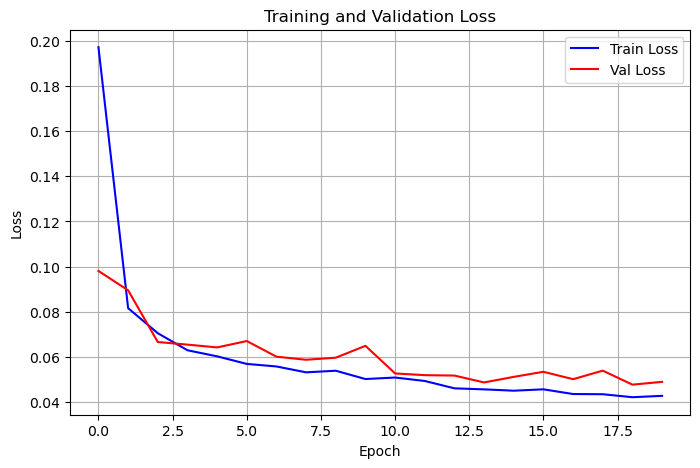

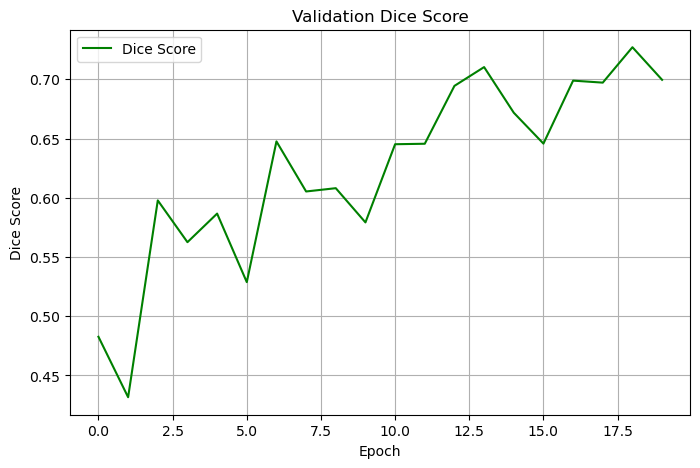

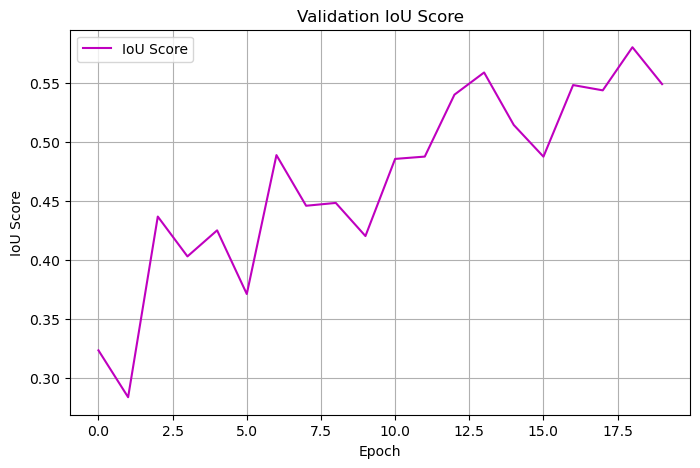

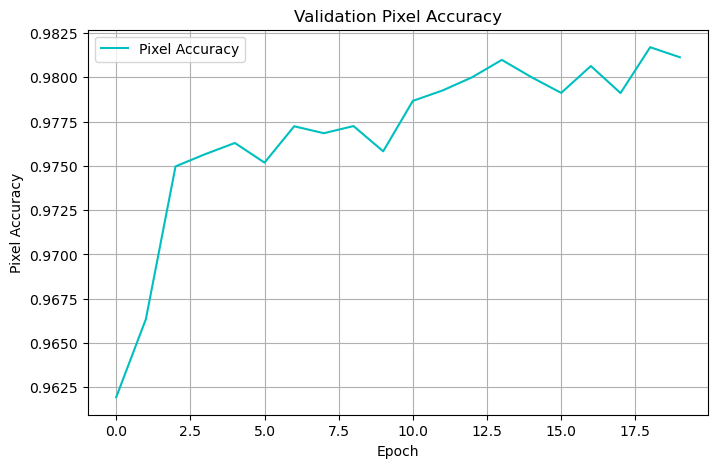

In [72]:
plt.figure(figsize=(8, 5))
plt.plot(range(num_epochs), train_losses_np, 'b-', label='Train Loss')
plt.plot(range(num_epochs), val_losses_np, 'r-', label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

# Plot Dice Score
plt.figure(figsize=(8, 5))
plt.plot(range(num_epochs), val_dices_np, 'g-', label='Dice Score')
plt.xlabel('Epoch')
plt.ylabel('Dice Score')
plt.title('Validation Dice Score')
plt.legend()
plt.grid(True)
plt.show()

# Plot IoU Score
plt.figure(figsize=(8, 5))
plt.plot(range(num_epochs), val_ious_np, 'm-', label='IoU Score')
plt.xlabel('Epoch')
plt.ylabel('IoU Score')
plt.title('Validation IoU Score')
plt.legend()
plt.grid(True)
plt.show()

# Plot Pixel Accuracy
plt.figure(figsize=(8, 5))
plt.plot(range(num_epochs), val_accs_np, 'c-', label='Pixel Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Pixel Accuracy')
plt.title('Validation Pixel Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [74]:
torch.save(model.state_dict(), 'model1_unet_resnet34.pth')
print("Model 1 weights saved as 'model1_unet_resnet34.pth'")

Model 1 weights saved as 'model1_unet_resnet34.pth'
